In [37]:
import json
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [38]:
PROJECT_ROOT = Path(r"D:\Pune-House-Price-Prediction")

DATA_CANDIDATES = [
    PROJECT_ROOT / "data" / "processed" / "pune_cleaned_reference_v2.csv",
    PROJECT_ROOT / "data" / "processed" / "pune_cleaned_reference.csv"
]

DATA_PATH = next(
    (path for path in DATA_CANDIDATES if path.exists()),
    None
)

MODEL_DIR = PROJECT_ROOT / "models"
VISUALIZATION_DIR = PROJECT_ROOT / "visualizations"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Cleaned CSV not found. Check the data/processed folder."
    )

print("Dataset:", DATA_PATH)
print("Model folder:", MODEL_DIR)

Dataset: D:\Pune-House-Price-Prediction\data\processed\pune_cleaned_reference.csv
Model folder: D:\Pune-House-Price-Prediction\models


In [39]:
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Rows: 27700
Columns: 53


,Unnamed: 0,balconies,bathroom,facing,floor,locality,neworold,opensides,price,addi_rooms,...,Dining Table,Gas connection,BED,Area,Residential,Villa,Independent,Penthouse,Apartment,Bedrooms
0,0,2.0,3.0,west,3.0,deccan gymkhana,new,2.0,27000000,NaN,...,no,yes,no,1611.0,no,no,no,no,"3 Bedrooms, 1 Hall, 1 Kitchen",3.0
1,1,NaN,2.0,northeast,1.0,kharadi,new,NaN,7610050,NaN,...,no,no,no,1279.0,no,no,no,no,"2 Bedrooms, 1 Hall, 1 Kitchen",2.0
2,2,NaN,1.0,northeast,1.0,sus,new,NaN,4100000,NaN,...,no,no,no,670.0,no,no,no,no,"1 Bedroom, 1 Hall, 1 Kitchen",1.0
3,3,NaN,2.0,northeast,1.0,bavdhan,new,NaN,5736000,NaN,...,no,no,no,956.0,no,no,no,no,"2 Bedrooms, 1 Hall, 1 Kitchen",2.0
4,4,1.0,3.0,west,6.0,deccan gymkhana,new,2.0,29002000,NaN,...,no,no,no,1706.0,no,no,no,no,"3 Bedrooms, 1 Hall, 1 Kitchen",3.0


In [40]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values in target:")
print(df["price"].isna().sum())

print("\nPrice summary:")
display(df["price"].describe())

Column names:
['Unnamed: 0', 'balconies', 'bathroom', 'facing', 'floor', 'locality', 'neworold', 'opensides', 'price', 'addi_rooms', 'Age', 'Lift Available', 'Car Parking', 'Power Backup', '24 X 7 Security', 'Children play area', 'Vaastu Compliant', 'Club House', 'Gymnasium', 'Swimming Pool', 'Sports Facility', 'Indoor Games', 'Jogging Track', 'Maintenance Staff', 'Intercom', 'Golf Course', 'Cafeteria', 'Rain Water Harvesting', 'Staff Quarter', 'Multipurpose Room', 'Landscaped Gardens', 'Shopping Mall', 'School', 'Hospital', 'ATM', 'AC', 'Wardrobe', 'TV', 'Refrigerator', 'Sofa', 'Washing Machine', 'Wifi', 'Microwave', 'Dining Table', 'Gas connection', 'BED', 'Area', 'Residential', 'Villa', 'Independent', 'Penthouse', 'Apartment', 'Bedrooms']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 27700 entries, 0 to 27699
Data columns (total 53 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0         

count    2.770000e+04
mean     1.526336e+07
std      1.704689e+07
min      4.700000e+05
25%      6.159000e+06
50%      9.000000e+06
75%      1.690000e+07
max      2.690000e+08
Name: price, dtype: float64

In [41]:
RAW_PATH = PROJECT_ROOT / "data" / "raw" / "Pune_property_data.csv"

if RAW_PATH.exists():
    raw_df = pd.read_csv(RAW_PATH)

    print("Raw dataset rows:", len(raw_df))
    print("Current cleaned dataset rows:", len(df))
    print("Difference in rows:", len(raw_df) - len(df))
else:
    print("Raw dataset not found; skipping row-count comparison.")

if len(df) < 1000:
    print("WARNING: Dataset is unexpectedly small. Verify the CSV before training.")

if len(df) < 37500:
    print(
        "WARNING: Current row count is lower than the expected "
        "approximately 37,517 cleaned rows. Check Notebook 1 and DATA_PATH."
    )

Raw dataset rows: 37539
Current cleaned dataset rows: 27700
Difference in rows: 9839


In [42]:
df["price"] = pd.to_numeric(df["price"], errors="coerce")

before_rows = len(df)

df = df.loc[
    df["price"].notna() & (df["price"] > 0)
].copy()

df.reset_index(drop=True, inplace=True)

print("Rows before target validation:", before_rows)
print("Rows after target validation:", len(df))
print("Invalid target rows removed:", before_rows - len(df))

Rows before target validation: 27700
Rows after target validation: 27700
Invalid target rows removed: 0


In [43]:
TARGET = "price"

# These columns are not useful model inputs.
# "Unnamed: 0" is a dataset index.
# "Apartment" is a descriptive field derived from Bedrooms.
DROP_COLUMNS = [
    "Unnamed: 0",
    "Apartment"
]

df = df.drop(
    columns=[col for col in DROP_COLUMNS if col in df.columns],
    errors="ignore"
)

print("Target:", TARGET)
print("Dataset shape:", df.shape)

Target: price
Dataset shape: (27700, 51)


In [44]:
AMENITY_COLUMNS = [
    "Lift Available",
    "Car Parking",
    "Power Backup",
    "24 X 7 Security",
    "Children play area",
    "Vaastu Compliant",
    "Club House",
    "Gymnasium",
    "Swimming Pool",
    "Sports Facility",
    "Indoor Games",
    "Jogging Track",
    "Maintenance Staff",
    "Intercom",
    "Golf Course",
    "Cafeteria",
    "Rain Water Harvesting",
    "Staff Quarter",
    "Multipurpose Room",
    "Landscaped Gardens",
    "Shopping Mall",
    "School",
    "Hospital",
    "ATM",
    "AC",
    "Wardrobe",
    "TV",
    "Refrigerator",
    "Sofa",
    "Washing Machine",
    "Wifi",
    "Microwave",
    "Dining Table",
    "Gas connection",
    "BED"
]

AMENITY_COLUMNS = [
    col for col in AMENITY_COLUMNS if col in df.columns
]

print("Amenity features found:", len(AMENITY_COLUMNS))
print(AMENITY_COLUMNS)

Amenity features found: 35
['Lift Available', 'Car Parking', 'Power Backup', '24 X 7 Security', 'Children play area', 'Vaastu Compliant', 'Club House', 'Gymnasium', 'Swimming Pool', 'Sports Facility', 'Indoor Games', 'Jogging Track', 'Maintenance Staff', 'Intercom', 'Golf Course', 'Cafeteria', 'Rain Water Harvesting', 'Staff Quarter', 'Multipurpose Room', 'Landscaped Gardens', 'Shopping Mall', 'School', 'Hospital', 'ATM', 'AC', 'Wardrobe', 'TV', 'Refrigerator', 'Sofa', 'Washing Machine', 'Wifi', 'Microwave', 'Dining Table', 'Gas connection', 'BED']


In [45]:
FEATURE_CANDIDATES = [
    "Area",
    "Bedrooms",
    "bathroom",
    "balconies",
    "floor",
    "opensides",
    "Age",
    "addi_rooms",
    "facing",
    "locality",
    "neworold",
    "Residential",
    "Villa",
    "Independent",
    "Penthouse"
]

FEATURES = [
    col for col in FEATURE_CANDIDATES if col in df.columns
]

FEATURES += AMENITY_COLUMNS

# Remove duplicates while preserving order
FEATURES = list(dict.fromkeys(FEATURES))

missing_candidates = [
    col for col in FEATURE_CANDIDATES if col not in df.columns
]

print("Features selected:", len(FEATURES))
print(FEATURES)

if missing_candidates:
    print("\nFeature columns not found in this CSV:")
    print(missing_candidates)

if not FEATURES:
    raise ValueError("No usable feature columns were found.")

Features selected: 50
['Area', 'Bedrooms', 'bathroom', 'balconies', 'floor', 'opensides', 'Age', 'addi_rooms', 'facing', 'locality', 'neworold', 'Residential', 'Villa', 'Independent', 'Penthouse', 'Lift Available', 'Car Parking', 'Power Backup', '24 X 7 Security', 'Children play area', 'Vaastu Compliant', 'Club House', 'Gymnasium', 'Swimming Pool', 'Sports Facility', 'Indoor Games', 'Jogging Track', 'Maintenance Staff', 'Intercom', 'Golf Course', 'Cafeteria', 'Rain Water Harvesting', 'Staff Quarter', 'Multipurpose Room', 'Landscaped Gardens', 'Shopping Mall', 'School', 'Hospital', 'ATM', 'AC', 'Wardrobe', 'TV', 'Refrigerator', 'Sofa', 'Washing Machine', 'Wifi', 'Microwave', 'Dining Table', 'Gas connection', 'BED']


In [46]:
X = df[FEATURES].copy()
y = df[TARGET].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head())
display(y.head())

X shape: (27700, 50)
y shape: (27700,)


,Area,Bedrooms,bathroom,balconies,floor,opensides,Age,addi_rooms,facing,locality,...,Wardrobe,TV,Refrigerator,Sofa,Washing Machine,Wifi,Microwave,Dining Table,Gas connection,BED
0,1611.0,3.0,3.0,2.0,3.0,2.0,3.0,NaN,west,deccan gymkhana,...,no,no,no,no,no,no,no,no,yes,no
1,1279.0,2.0,2.0,NaN,1.0,NaN,1.0,NaN,northeast,kharadi,...,no,no,no,no,no,no,no,no,no,no
2,670.0,1.0,1.0,NaN,1.0,NaN,1.0,NaN,northeast,sus,...,no,no,no,no,no,no,no,no,no,no
3,956.0,2.0,2.0,NaN,1.0,NaN,3.0,NaN,northeast,bavdhan,...,no,no,no,no,no,no,no,no,no,no
4,1706.0,3.0,3.0,1.0,6.0,2.0,1.0,NaN,west,deccan gymkhana,...,no,no,no,no,no,no,no,no,no,no


0    27000000
1     7610050
2     4100000
3     5736000
4    29002000
Name: price, dtype: int64

In [47]:
for column in AMENITY_COLUMNS:
    values = (
        X[column]
        .astype("string")
        .str.strip()
        .str.lower()
        .replace({
            "1": "yes",
            "0": "no",
            "true": "yes",
            "false": "no",
            "": pd.NA,
            "nan": pd.NA,
            "none": pd.NA
        })
    )

    X[column] = values.astype(object).where(values.notna(), np.nan)

print("Amenity values standardized.")

Amenity values standardized.


In [48]:
NUMERIC_COLUMNS = [
    col for col in FEATURES
    if col not in AMENITY_COLUMNS
    and pd.api.types.is_numeric_dtype(X[col])
]

CATEGORICAL_COLUMNS = [
    col for col in FEATURES
    if col not in NUMERIC_COLUMNS
]

print("Numeric features:", NUMERIC_COLUMNS)
print("\nCategorical features:", CATEGORICAL_COLUMNS)

Numeric features: ['Area', 'Bedrooms', 'bathroom', 'balconies', 'floor', 'opensides', 'Age', 'addi_rooms']

Categorical features: ['facing', 'locality', 'neworold', 'Residential', 'Villa', 'Independent', 'Penthouse', 'Lift Available', 'Car Parking', 'Power Backup', '24 X 7 Security', 'Children play area', 'Vaastu Compliant', 'Club House', 'Gymnasium', 'Swimming Pool', 'Sports Facility', 'Indoor Games', 'Jogging Track', 'Maintenance Staff', 'Intercom', 'Golf Course', 'Cafeteria', 'Rain Water Harvesting', 'Staff Quarter', 'Multipurpose Room', 'Landscaped Gardens', 'Shopping Mall', 'School', 'Hospital', 'ATM', 'AC', 'Wardrobe', 'TV', 'Refrigerator', 'Sofa', 'Washing Machine', 'Wifi', 'Microwave', 'Dining Table', 'Gas connection', 'BED']


In [49]:
for column in NUMERIC_COLUMNS:
    X[column] = pd.to_numeric(X[column], errors="coerce")

print("Numeric columns converted.")

Numeric columns converted.


In [50]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training percentage:", round(len(X_train) / len(X) * 100, 2), "%")
print("Testing percentage:", round(len(X_test) / len(X) * 100, 2), "%")

Training rows: 22160
Testing rows: 5540
Training percentage: 80.0 %
Testing percentage: 20.0 %


In [51]:
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Not specified"
            )
        ),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, NUMERIC_COLUMNS),
        ("categorical", categorical_pipeline, CATEGORICAL_COLUMNS)
    ],
    remainder="drop"
)

print("Preprocessing pipeline updated.")

Preprocessing pipeline updated.


In [52]:
# Convert pandas nullable values (pd.NA) into standard NumPy NaN

for column in NUMERIC_COLUMNS:
    X[column] = pd.to_numeric(
        X[column], errors="coerce"
    ).astype(float)

for column in CATEGORICAL_COLUMNS:
    X[column] = (
        X[column]
        .astype("object")
        .where(X[column].notna(), np.nan)
    )

# Re-create the train-test split after cleaning X

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Missing values standardized.")
print("Remaining pandas nullable values:", int(
    X.apply(lambda col: col.map(lambda value: value is pd.NA).sum()).sum()
))
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Missing values standardized.
Remaining pandas nullable values: 0
Training shape: (22160, 50)
Testing shape: (5540, 50)


In [53]:
models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

print("Models ready:", list(models.keys()))

Models ready: ['Random Forest', 'Extra Trees']


In [54]:
results = []
trained_pipelines = {}

for model_name, model in models.items():
    print(f"\nTraining {model_name}...")

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    trained_pipelines[model_name] = pipeline

    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("R²:", round(r2, 4))

print("\nTraining and evaluation completed.")


Training Random Forest...
MAE: 1995268.19
RMSE: 4967343.16
R²: 0.9249

Training Extra Trees...
MAE: 1809764.52
RMSE: 4836665.7
R²: 0.9288

Training and evaluation completed.


In [55]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values("MAE").reset_index(drop=True)

display(results_df)

,Model,MAE,RMSE,R2
0,Extra Trees,1.809765e+06,4.836666e+06,0.928841
1,Random Forest,1.995268e+06,4.967343e+06,0.924944


In [56]:
metrics_path = MODEL_DIR / "model_comparison.csv"

results_df.to_csv(metrics_path, index=False)

print("Metrics saved to:", metrics_path)

Metrics saved to: D:\Pune-House-Price-Prediction\models\model_comparison.csv


In [57]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_pipelines[best_model_name]

print("Best model by test MAE:", best_model_name)
display(results_df.iloc[[0]])

Best model by test MAE: Extra Trees


,Model,MAE,RMSE,R2
0,Extra Trees,1.809765e+06,4.836666e+06,0.928841


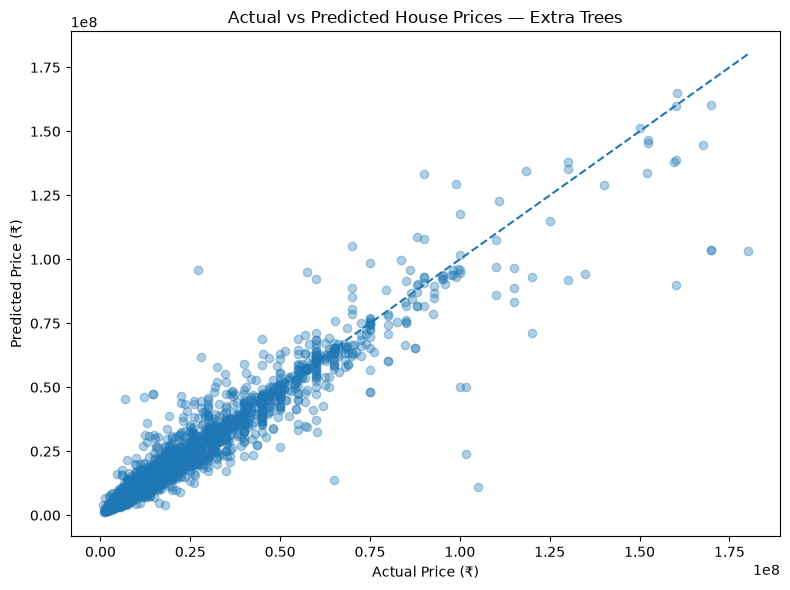

Plot saved to: D:\Pune-House-Price-Prediction\visualizations\actual_vs_predicted.png


In [58]:
best_predictions = best_model.predict(X_test)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, best_predictions, alpha=0.35)

min_price = min(y_test.min(), best_predictions.min())
max_price = max(y_test.max(), best_predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Price (₹)")
plt.ylabel("Predicted Price (₹)")
plt.title(f"Actual vs Predicted House Prices — {best_model_name}")
plt.tight_layout()

plot_path = VISUALIZATION_DIR / "actual_vs_predicted.png"
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()

print("Plot saved to:", plot_path)

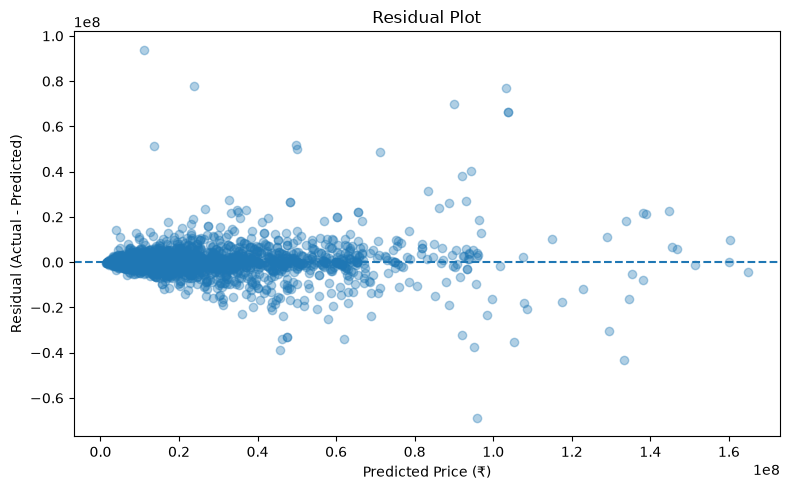

Residual plot saved to: D:\Pune-House-Price-Prediction\visualizations\residual_plot.png


In [59]:
residuals = y_test.to_numpy() - best_predictions

plt.figure(figsize=(8, 5))
plt.scatter(best_predictions, residuals, alpha=0.35)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Price (₹)")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot")
plt.tight_layout()

residual_path = VISUALIZATION_DIR / "residual_plot.png"
plt.savefig(residual_path, dpi=150, bbox_inches="tight")
plt.show()

print("Residual plot saved to:", residual_path)

,Feature,Importance
0,numeric__Area,0.389077
1,numeric__Bedrooms,0.200871
2,numeric__bathroom,0.179559
157,categorical__locality_kharadi,0.030016
168,categorical__locality_koregaon park,0.029187
142,categorical__locality_kalyani nagar,0.017892
289,categorical__locality_sangamvadi,0.015778
77,categorical__locality_boat club road,0.015536
351,categorical__locality_wagholi,0.008304
6,numeric__Age,0.007002


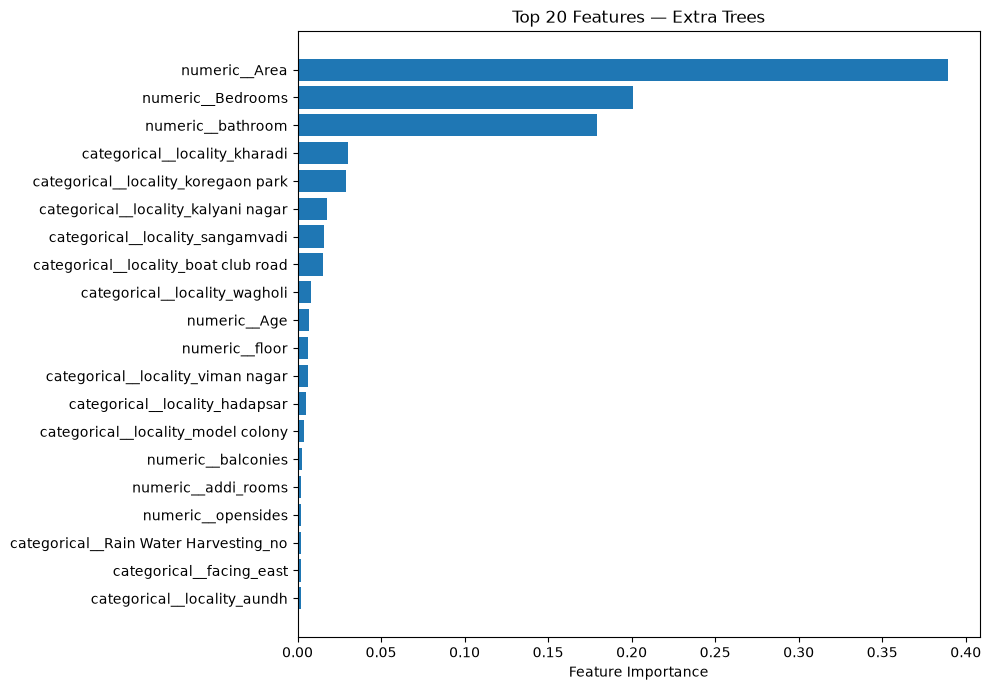

Feature importance saved to: D:\Pune-House-Price-Prediction\visualizations\feature_importance.png


In [60]:
model_step = best_model.named_steps["model"]
preprocessor_step = best_model.named_steps["preprocessor"]

encoded_feature_names = preprocessor_step.get_feature_names_out()

if hasattr(model_step, "feature_importances_"):
    importance_df = pd.DataFrame({
        "Feature": encoded_feature_names,
        "Importance": model_step.feature_importances_
    }).sort_values("Importance", ascending=False)

    display(importance_df.head(20))

    plt.figure(figsize=(10, 7))
    top_features = importance_df.head(20).sort_values("Importance")

    plt.barh(
        top_features["Feature"],
        top_features["Importance"]
    )

    plt.xlabel("Feature Importance")
    plt.title(f"Top 20 Features — {best_model_name}")
    plt.tight_layout()

    importance_path = VISUALIZATION_DIR / "feature_importance.png"
    plt.savefig(importance_path, dpi=150, bbox_inches="tight")
    plt.show()

    print("Feature importance saved to:", importance_path)
else:
    print("Selected model does not expose feature_importances_.")

In [61]:
baseline = DummyRegressor(strategy="median")
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)
baseline_r2 = r2_score(y_test, baseline_predictions)

print("Baseline Model: Median Price")
print("MAE:", round(baseline_mae, 2))
print("RMSE:", round(baseline_rmse, 2))
print("R²:", round(baseline_r2, 4))

print("\nBest trained model MAE:", round(
    mean_absolute_error(y_test, best_predictions), 2
))

Baseline Model: Median Price
MAE: 9785378.4
RMSE: 19340334.43
R²: -0.1378

Best trained model MAE: 1809764.52


In [62]:
MODEL_PATH = MODEL_DIR / "best_house_price_model.joblib"

joblib.dump(best_model, MODEL_PATH)

print("Model saved successfully!")
print("Saved path:", MODEL_PATH)

Model saved successfully!
Saved path: D:\Pune-House-Price-Prediction\models\best_house_price_model.joblib


In [63]:
feature_config = {
    "target": TARGET,
    "features": FEATURES,
    "numeric_columns": NUMERIC_COLUMNS,
    "categorical_columns": CATEGORICAL_COLUMNS,
    "amenity_columns": AMENITY_COLUMNS,
    "selected_model": best_model_name,
    "target_unit": "INR"
}

CONFIG_PATH = MODEL_DIR / "model_features.json"

with open(CONFIG_PATH, "w", encoding="utf-8") as file:
    json.dump(feature_config, file, indent=4)

print("Feature configuration saved to:", CONFIG_PATH)

Feature configuration saved to: D:\Pune-House-Price-Prediction\models\model_features.json


In [64]:
best_row = results_df.iloc[0]

report = {
    "dataset_file": DATA_PATH.name,
    "dataset_rows_used": int(len(df)),
    "number_of_features": int(len(FEATURES)),
    "number_of_amenities": int(len(AMENITY_COLUMNS)),
    "training_rows": int(len(X_train)),
    "testing_rows": int(len(X_test)),
    "selected_model": str(best_model_name),
    "mae": float(best_row["MAE"]),
    "rmse": float(best_row["RMSE"]),
    "r2": float(best_row["R2"]),
    "random_state": 42,
    "test_size": 0.20
}

REPORT_PATH = MODEL_DIR / "model_report.json"

with open(REPORT_PATH, "w", encoding="utf-8") as file:
    json.dump(report, file, indent=4)

print(json.dumps(report, indent=4))

{
    "dataset_file": "pune_cleaned_reference.csv",
    "dataset_rows_used": 27700,
    "number_of_features": 50,
    "number_of_amenities": 35,
    "training_rows": 22160,
    "testing_rows": 5540,
    "selected_model": "Extra Trees",
    "mae": 1809764.5211226745,
    "rmse": 4836665.698415562,
    "r2": 0.9288407252775713,
    "random_state": 42,
    "test_size": 0.2
}


In [65]:
loaded_model = joblib.load(MODEL_PATH)

sample_property = X_test.iloc[[0]].copy()

actual_price = float(y_test.iloc[0])
predicted_price = float(loaded_model.predict(sample_property)[0])

print("Sample property:")
display(sample_property)

print(f"Actual price: ₹{actual_price:,.0f}")
print(f"Predicted price: ₹{predicted_price:,.0f}")
print(f"Absolute error: ₹{abs(actual_price - predicted_price):,.0f}")

Sample property:


,Area,Bedrooms,bathroom,balconies,floor,opensides,Age,addi_rooms,facing,locality,...,Wardrobe,TV,Refrigerator,Sofa,Washing Machine,Wifi,Microwave,Dining Table,Gas connection,BED
7258,1150.0,2.0,2.0,2.0,2.0,2.0,6.0,NaN,east,pimple saudagar,...,no,no,no,no,no,no,yes,no,no,no


Actual price: ₹6,600,000
Predicted price: ₹7,468,190
Absolute error: ₹868,190


In [66]:
print("=" * 55)
print("PUNE HOUSE PRICE PREDICTION — MODEL TRAINING SUMMARY")
print("=" * 55)

print("Dataset:", DATA_PATH.name)
print("Rows used:", len(df))
print("Features:", len(FEATURES))
print("Amenity features:", len(AMENITY_COLUMNS))
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Selected model:", best_model_name)
print(f"MAE: ₹{best_row['MAE']:,.2f}")
print(f"RMSE: ₹{best_row['RMSE']:,.2f}")
print(f"R²: {best_row['R2']:.4f}")

print("\nSaved files:")
for path in [
    MODEL_PATH,
    CONFIG_PATH,
    REPORT_PATH,
    metrics_path,
    VISUALIZATION_DIR / "actual_vs_predicted.png",
    VISUALIZATION_DIR / "residual_plot.png",
    VISUALIZATION_DIR / "feature_importance.png"
]:
    print(f"{'OK' if path.exists() else 'Not created'}: {path}")

PUNE HOUSE PRICE PREDICTION — MODEL TRAINING SUMMARY
Dataset: pune_cleaned_reference.csv
Rows used: 27700
Features: 50
Amenity features: 35
Training rows: 22160
Testing rows: 5540
Selected model: Extra Trees
MAE: ₹1,809,764.52
RMSE: ₹4,836,665.70
R²: 0.9288

Saved files:
OK: D:\Pune-House-Price-Prediction\models\best_house_price_model.joblib
OK: D:\Pune-House-Price-Prediction\models\model_features.json
OK: D:\Pune-House-Price-Prediction\models\model_report.json
OK: D:\Pune-House-Price-Prediction\models\model_comparison.csv
OK: D:\Pune-House-Price-Prediction\visualizations\actual_vs_predicted.png
OK: D:\Pune-House-Price-Prediction\visualizations\residual_plot.png
OK: D:\Pune-House-Price-Prediction\visualizations\feature_importance.png
